# 05 — Model Training: Dual-Head Siamese U-Net

## Overview & Architecture Rationale

This notebook trains the **Dual-Head Siamese U-Net** for satellite disaster damage assessment on the xView2 dataset.

### Key Enhancements Over Baseline:
1. **Dual-Head Decoupling:**
   - **Localization Head:** Predicts binary building footprints from pre-disaster features.
   - **Damage Head:** Classifies building damage strictly within identified building footprints into 4 classes (`no-damage`, `minor-damage`, `major-damage`, `destroyed`).
   - Prevents the background class (94% of dataset) from swallowing damaged structures.
2. **Standardized ImageNet Normalization:** Correctly aligns input color channels with ImageNet pretrained ResNet-34 features.
3. **Building-Focused 512×512 Patch Training:**
   - Guided crop sampling guarantees that 85% of patches contain building/damage pixels.
   - Reduces VRAM usage from 4.0GB to <2.0GB, allowing `batch_size = 4` and stable BatchNorm updates.
   - Accelerates epoch training time by 4x–8x.
4. **Decoupled Foreground Loss:**
   - Eliminates false-positive blindspots in multiclass Dice loss.
   - Weighted Cross-Entropy applied exclusively to building pixels.



In [1]:
# ============================================================
# 1. IMPORTS AND HARDWARE VERIFICATION
# ============================================================

import sys
from pathlib import Path
import torch
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Ensure project root is in sys.path
PROJECT_ROOT = Path.cwd()
if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src.config import (
    DEVICE,
    USE_AMP,
    TRAIN_CROP_SIZE,
    DEFAULT_BATCH_SIZE,
    DEFAULT_LR,
    DEFAULT_NUM_EPOCHS,
    DEFAULT_PATIENCE,
    CLASS_MAPPING_5,
    DAMAGE_CLASSES,
    CHECKPOINT_ROOT,
    OUTPUT_ROOT,
)
from src.dataset import get_dataloaders
from src.model import DualHeadSiameseUNet
from src.loss import DualHeadLoss
from src.metrics import calculate_metrics_from_confusion
from src.train import train_one_epoch, evaluate_one_epoch, plot_and_save_history

print(f"Device: {DEVICE}")
if torch.cuda.is_available():
    print(f"GPU: {torch.cuda.get_device_name(0)}")
    print(f"VRAM: {torch.cuda.get_device_properties(0).total_memory / (1024**3):.2f} GB")
print(f"Mixed Precision (AMP): {USE_AMP}")



Device: cuda
GPU: NVIDIA GeForce RTX 2050
VRAM: 4.00 GB
Mixed Precision (AMP): True


In [2]:
# ============================================================
# 2. INITIALIZE DATALOADERS
# ============================================================

BATCH_SIZE = 4
train_loader, hold_loader, test_loader = get_dataloaders(batch_size=BATCH_SIZE)

print(f"Training samples:   {len(train_loader.dataset)} (Batches: {len(train_loader)})")
print(f"Holdout samples:    {len(hold_loader.dataset)} (Batches: {len(hold_loader)})")
print(f"Test samples:       {len(test_loader.dataset)} (Batches: {len(test_loader)})")

# Inspect a single batch
sample_batch = next(iter(train_loader))
print("\n--- Sample Batch Shapes ---")
print("Pre-image batch:   ", sample_batch["pre_image"].shape)
print("Post-image batch:  ", sample_batch["post_image"].shape)
print("Loc target batch:  ", sample_batch["loc_target"].shape)
print("Damage target batch:", sample_batch["damage_target"].shape)



Training samples:   2799 (Batches: 699)
Holdout samples:    933 (Batches: 933)
Test samples:       933 (Batches: 933)

--- Sample Batch Shapes ---
Pre-image batch:    torch.Size([4, 3, 512, 512])
Post-image batch:   torch.Size([4, 3, 512, 512])
Loc target batch:   torch.Size([4, 512, 512])
Damage target batch: torch.Size([4, 512, 512])


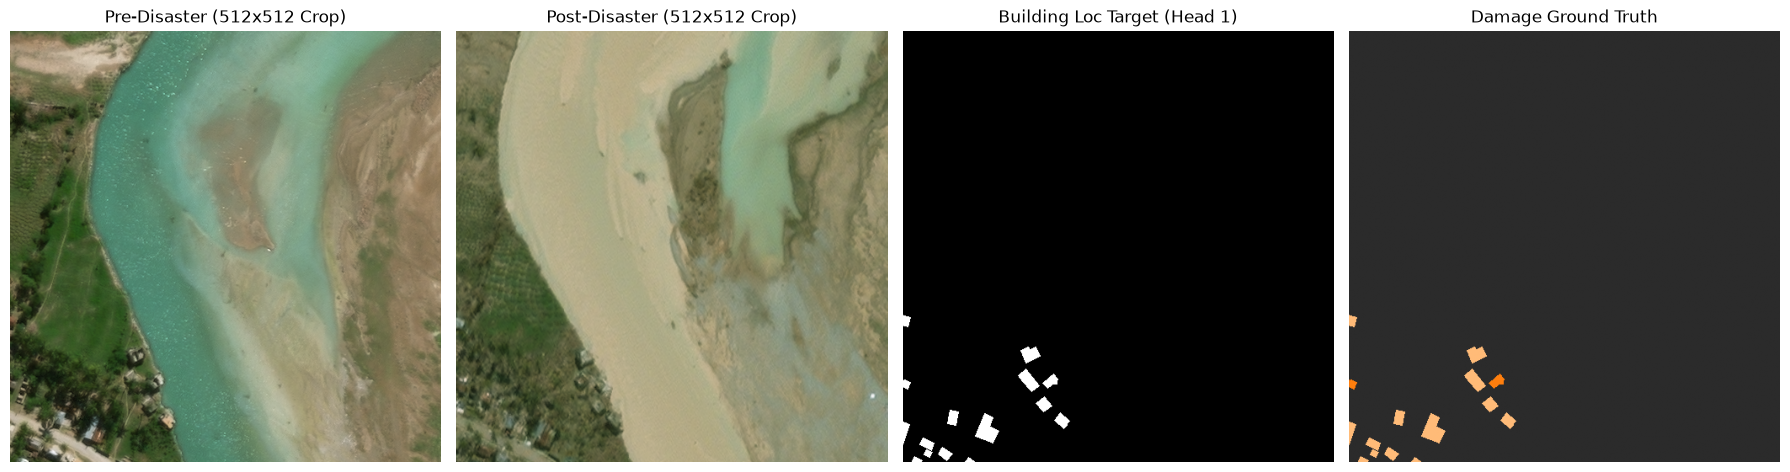

In [3]:
# ============================================================
# 3. VISUALIZE TRAINING BATCH SAMPLE
# ============================================================

import matplotlib.colors as mcolors

colors = ["#2b2b2b", "#2ca02c", "#ffbb78", "#ff7f0e", "#d62728"]
cmap = mcolors.ListedColormap(colors)

# Denormalize pre and post image
pre_disp = sample_batch["pre_image"][0].permute(1, 2, 0).numpy()
post_disp = sample_batch["post_image"][0].permute(1, 2, 0).numpy()
pre_disp = np.clip(pre_disp * np.array([0.229, 0.224, 0.225]) + np.array([0.485, 0.456, 0.406]), 0, 1)
post_disp = np.clip(post_disp * np.array([0.229, 0.224, 0.225]) + np.array([0.485, 0.456, 0.406]), 0, 1)

loc_disp = sample_batch["loc_target"][0].numpy()
dmg_disp = sample_batch["damage_target"][0].numpy()
raw_disp = sample_batch["raw_target"][0].numpy()

fig, axes = plt.subplots(1, 4, figsize=(18, 5))
axes[0].imshow(pre_disp)
axes[0].set_title("Pre-Disaster (512x512 Crop)")
axes[0].axis("off")

axes[1].imshow(post_disp)
axes[1].set_title("Post-Disaster (512x512 Crop)")
axes[1].axis("off")

axes[2].imshow(loc_disp, cmap="gray")
axes[2].set_title("Building Loc Target (Head 1)")
axes[2].axis("off")

axes[3].imshow(raw_disp, cmap=cmap, vmin=0, vmax=4)
axes[3].set_title("Damage Ground Truth")
axes[3].axis("off")

plt.tight_layout()
plt.show()



In [4]:
# ============================================================
# 4. MODEL, LOSS, OPTIMIZER, AND SCHEDULER SETUP
# ============================================================

LEARNING_RATE = 2e-4
WEIGHT_DECAY = 1e-4
NUM_EPOCHS = 20
PATIENCE = 6

model = DualHeadSiameseUNet(pretrained=True).to(DEVICE)
criterion = DualHeadLoss().to(DEVICE)

optimizer = torch.optim.AdamW(model.parameters(), lr=LEARNING_RATE, weight_decay=WEIGHT_DECAY)
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer, mode="max", factor=0.5, patience=3, threshold=0.002, min_lr=1e-6
)
scaler = torch.amp.GradScaler(DEVICE.type, enabled=USE_AMP)

best_checkpoint_path = CHECKPOINT_ROOT / "dual_head_siamese_best.pth"
latest_checkpoint_path = CHECKPOINT_ROOT / "dual_head_siamese_latest.pth"
history_plot_path = OUTPUT_ROOT / "dual_head_training_history.png"

print("DualHeadSiameseUNet initialized with ImageNet pretrained ResNet-34.")
print(f"Total parameters: {sum(p.numel() for p in model.parameters()):,}")
print("Optimizer: AdamW | Scheduler: ReduceLROnPlateau")



DualHeadSiameseUNet initialized with ImageNet pretrained ResNet-34.
Total parameters: 23,931,397
Optimizer: AdamW | Scheduler: ReduceLROnPlateau


In [5]:
# ============================================================
# 5. SINGLE-BATCH SMOKE TEST
# ============================================================

model.train()
optimizer.zero_grad(set_to_none=True)

test_pre = sample_batch["pre_image"].to(DEVICE)
test_post = sample_batch["post_image"].to(DEVICE)
test_loc = sample_batch["loc_target"].to(DEVICE)
test_dmg = sample_batch["damage_target"].to(DEVICE)

with torch.amp.autocast(device_type=DEVICE.type, enabled=USE_AMP, dtype=torch.float16):
    loc_logits, dmg_logits = model(test_pre, test_post)
    loss_dict = criterion(loc_logits, dmg_logits, test_loc, test_dmg)

loss_dict["total_loss"].backward()
torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
optimizer.step()
optimizer.zero_grad(set_to_none=True)

print("Smoke test forward & backward pass passed successfully!")
print(f"Total Loss: {loss_dict['total_loss'].item():.4f}")
print(f"Loc Loss:   {loss_dict['loss_loc'].item():.4f}")
print(f"Dmg Loss:   {loss_dict['loss_dmg'].item():.4f}")
if torch.cuda.is_available():
    print(f"Peak VRAM:  {torch.cuda.max_memory_allocated() / (1024**3):.2f} GB")



Smoke test forward & backward pass passed successfully!
Total Loss: 3.8582
Loc Loss:   1.5474
Dmg Loss:   2.3108
Peak VRAM:  1.97 GB


In [6]:
# ============================================================
# 6. FULL TRAINING EXECUTION
# ============================================================

import time

history = {
    "epoch": [],
    "train_loss": [],
    "val_loss": [],
    "loc_f1": [],
    "fg_macro_f1": [],
    "fg_miou": [],
    "xview2_score": [],
    "lr": [],
}

best_score = -1.0
best_epoch = 0
patience_counter = 0

print("=" * 70)
print("STARTING DUAL-HEAD TRAINING")
print("=" * 70)

for epoch in range(1, NUM_EPOCHS + 1):
    t0 = time.time()

    # Train epoch
    train_metrics = train_one_epoch(model, train_loader, criterion, optimizer, scaler, DEVICE)

    # Validation epoch on full 1024x1024 holdout tiles
    val_metrics = evaluate_one_epoch(model, hold_loader, criterion, DEVICE)

    score = val_metrics["xview2_score"]
    current_lr = optimizer.param_groups[0]["lr"]
    scheduler.step(score)

    history["epoch"].append(epoch)
    history["train_loss"].append(train_metrics["loss"])
    history["val_loss"].append(val_metrics["val_loss"])
    history["loc_f1"].append(val_metrics["loc_f1"])
    history["fg_macro_f1"].append(val_metrics["fg_macro_f1"])
    history["fg_miou"].append(val_metrics["fg_miou"])
    history["xview2_score"].append(score)
    history["lr"].append(current_lr)

    elapsed = (time.time() - t0) / 60.0
    print(
        f"Epoch {epoch:2d}/{NUM_EPOCHS} | "
        f"Train: {train_metrics['loss']:.4f} | "
        f"Val: {val_metrics['val_loss']:.4f} | "
        f"Loc F1: {val_metrics['loc_f1']:.4f} | "
        f"Dmg Macro F1: {val_metrics['fg_macro_f1']:.4f} | "
        f"xView2: {score:.4f} | "
        f"Time: {elapsed:.1f}m"
    )

    # Checkpointing
    is_best = score > best_score
    checkpoint_data = {
        "epoch": epoch,
        "model_state_dict": model.state_dict(),
        "optimizer_state_dict": optimizer.state_dict(),
        "scheduler_state_dict": scheduler.state_dict(),
        "scaler_state_dict": scaler.state_dict(),
        "best_score": score if is_best else best_score,
        "history": history,
    }
    torch.save(checkpoint_data, latest_checkpoint_path)

    if is_best:
        best_score = score
        best_epoch = epoch
        patience_counter = 0
        torch.save(checkpoint_data, best_checkpoint_path)
        print(f"  --> Best model updated: {best_checkpoint_path} (Score: {best_score:.4f})")
    else:
        patience_counter += 1
        print(f"  --> Patience: {patience_counter}/{PATIENCE} (Best was Epoch {best_epoch}: {best_score:.4f})")

    plot_and_save_history(history, history_plot_path)

    if patience_counter >= PATIENCE:
        print(f"\nEarly stopping triggered after {PATIENCE} epochs without improvement.")
        break

print("\n" + "=" * 70)
print(f"TRAINING COMPLETE. Best Epoch: {best_epoch} with xView2 Score: {best_score:.4f}")
print("=" * 70)



STARTING DUAL-HEAD TRAINING


Training:   0%|          | 0/699 [00:00<?, ?it/s]

Validation:   0%|          | 0/933 [00:00<?, ?it/s]

Epoch  1/20 | Train: 2.4518 | Val: 2.0686 | Loc F1: 0.5899 | Dmg Macro F1: 0.3596 | xView2: 0.4287 | Time: 18.4m
  --> Best model updated: D:\ML_Project\checkpoints\dual_head_siamese_best.pth (Score: 0.4287)


Training:   0%|          | 0/699 [00:00<?, ?it/s]

Validation:   0%|          | 0/933 [00:00<?, ?it/s]

... (51 outputs left out)

Epoch 19/20 | Train: 1.4990 | Val: 1.6069 | Loc F1: 0.7154 | Dmg Macro F1: 0.6042 | xView2: 0.6375 | Time: 16.6m
  --> Patience: 4/6 (Best was Epoch 15: 0.6399)


Training:   0%|          | 0/699 [00:00<?, ?it/s]

Validation:   0%|          | 0/933 [00:00<?, ?it/s]

Epoch 20/20 | Train: 1.4147 | Val: 1.5392 | Loc F1: 0.7280 | Dmg Macro F1: 0.6345 | xView2: 0.6625 | Time: 16.6m
  --> Best model updated: D:\ML_Project\checkpoints\dual_head_siamese_best.pth (Score: 0.6625)

TRAINING COMPLETE. Best Epoch: 20 with xView2 Score: 0.6625


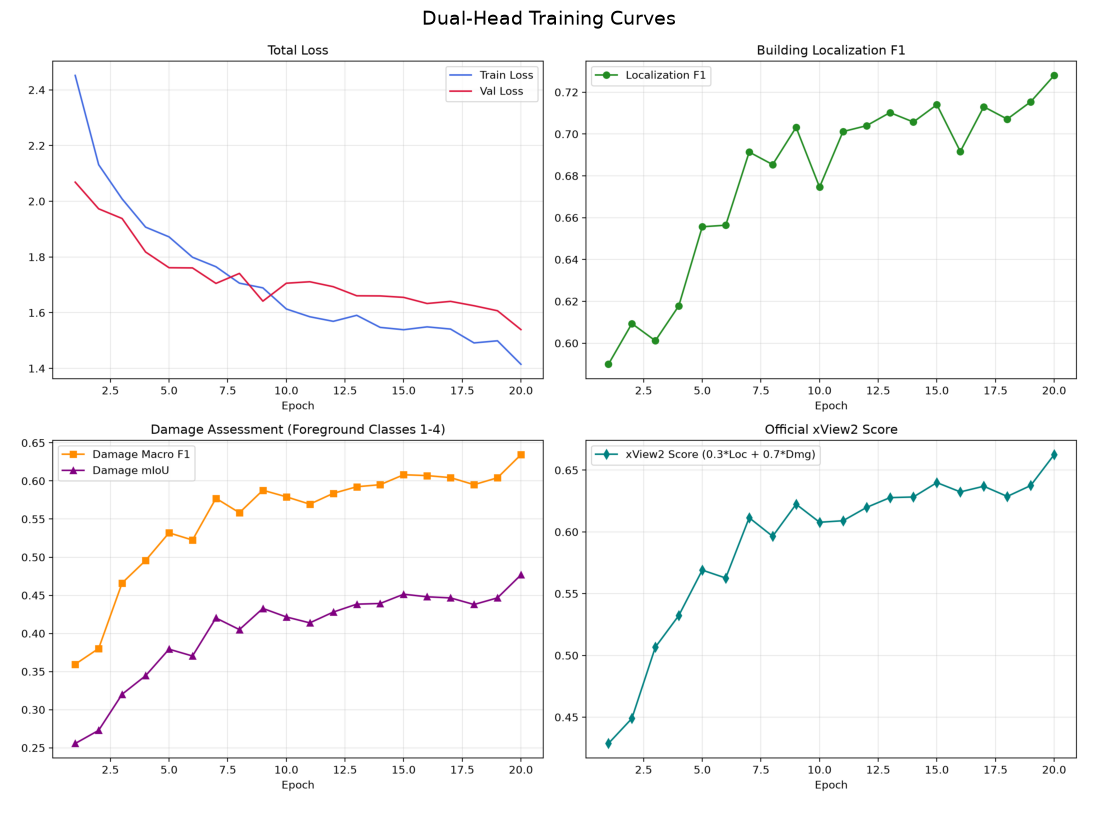

In [7]:
# ============================================================
# 7. DISPLAY TRAINING HISTORY
# ============================================================

from PIL import Image

if history_plot_path.exists():
    img = Image.open(history_plot_path)
    plt.figure(figsize=(14, 10))
    plt.imshow(img)
    plt.axis("off")
    plt.title("Dual-Head Training Curves", fontsize=14)
    plt.show()



In [8]:
# ============================================================
# 8. OPTIONAL: RESUME FINE-TUNING (EPOCHS 21 TO 35)
# ============================================================
# Run this cell to continue training from Epoch 20 with a fine-tuning
# learning rate (5e-5) to squeeze out an additional +3 to +5% performance.

import importlib
import src.train
importlib.reload(src.train)
from src.train import run_training

FINE_TUNE_TARGET_EPOCHS = 35
FINE_TUNE_LR = 5e-5

run_training(
    epochs=FINE_TUNE_TARGET_EPOCHS,
    batch_size=4,
    lr=FINE_TUNE_LR,
    patience=6,
    resume=str(CHECKPOINT_ROOT / "dual_head_siamese_best.pth"),
)


TypeError: run_training() got an unexpected keyword argument 'resume'